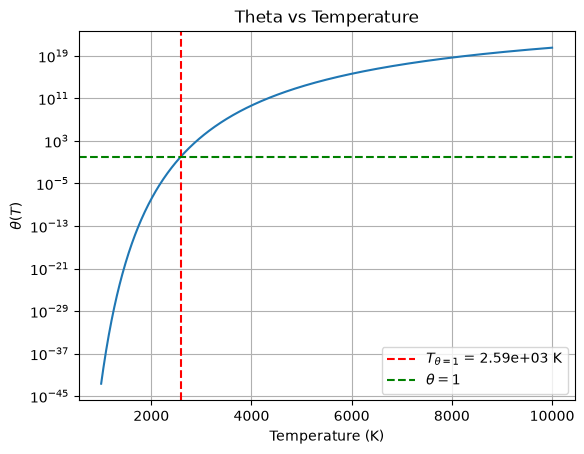

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

V = 1.0
N = 1.0  # Replace with the electron-gas particle number
T = np.linspace(1000, 10000, 1000)
kb = 1.380649e-23
hbar = 1.0545718e-34
me = 9.10938356e-31
I = -13.6 * 1.60218e-19  # Negative neutral-state energy

def log_theta(temp):
    lambda_T = np.sqrt(2 * np.pi * hbar**2 / (me * kb * temp))
    return np.log(V / (N * lambda_T**3)) + I / (kb * temp)

Tcrit = brentq(log_theta, T[0], T[-1])

lambda_T = np.sqrt(2 * np.pi * hbar**2 / (me * kb * T))
theta = V / (N * lambda_T**3) * np.exp(I / (kb * T))

plt.semilogy(T, theta)
plt.xlabel('Temperature (K)')
plt.ylabel(r'$\theta(T)$')
plt.title('Theta vs Temperature')
plt.axvline(Tcrit, color='r', linestyle='--',
            label=f'$T_{{\\theta=1}}$ = {Tcrit:.2e} K')
plt.axhline(1, color='g', linestyle='--', label=r'$\theta=1$')
plt.grid()
plt.legend()
plt.savefig('theta_vs_temperature.png')
plt.show()